# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

## Functions

In [2]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [3]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(6288, 7)

In [4]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(300, 4)

In [5]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(300, 2658)

In [6]:
words2remove = []

In [7]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [8]:
# explained_variance_ratio_goal = 0.8
# pca = PCA(n_components=explained_variance_ratio_goal)
# pca.fit(df_vectorized)
# n_components = pca.n_components_
# n_components

In [9]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# # X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
# X = pca.transform(X) # Use fitted PCA with 95% of explained variance
# df_vectorized = pd.DataFrame(X)

# # Normalize
# X = X / np.linalg.norm(X, axis=1, keepdims=True)
# df_vectorized = pd.DataFrame(X)

In [10]:
X_original.shape

(300, 2658)

# KNN search

In [11]:
n_neighbors = 50
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

# query_text = "physics informed reinforcement learning"
query_text = "The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters."
# query_text = "Control strategy, closed loop, nested, submodules, capacitor voltage control, circulating currents, common mode voltage, current control, model predictive control, proportional integral controller, modeling, total cluster intercluster capacitor energy balance balancing, low frequency oscillation mitigation."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = vectorizer.transform(query_text).toarray()

# Dimensionality reduction
# query_text_vec = pca.transform(query_text_vec)

print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    display(f"Neighbor {i+1}, Index: {knn_idx}, Title: {data['title'][knn_idx]}")
    display(f"Abstract {data['html_url'][knn_idx]}: {data['abstract'][knn_idx]}")

The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters.
['artificial intelligence deep learning imitation learning reinforcement learning neural network power converter']
[[0. 0. 0. ... 0. 0. 0.]]


'Neighbor 1, Index: 109, Title: a comprehensive power flow approach for multi terminal vsc hvdc system considering cross regional primary frequency responses'

'Abstract https://ieeexplore.ieee.org/document/8967191/: for the planning operation and control of multiterminal voltage source converter vsc based high voltage direct current hvdc vsc mtdc systems an accurate power flow formulation is a key starting point conventional power flow formulations assume the constant frequencies for all asynchronous ac systems therefore a new feature about the complex coupling relations between ac frequencies dc voltages and the exchanged power via vsc stations can not be characterized if vsc mtdc systems are required to provide cross regional frequency responses to address this issue this paper proposes a comprehensive frequency dependent power flow formulation the proposed approach takes the frequencies of asynchronous ac systems as explicit variables and investigates the novel bus models of the interlinking buses of vsc stations the proposed approach accommodates different operation modes and frequency droop strategies of vsc stations and considers the p

'Neighbor 2, Index: 29, Title: a bidirectional modular multilevel resonant dc dc converter for wide voltage range medium voltage power conversion'

'Abstract https://ieeexplore.ieee.org/document/10179975/: the arm inductor is found to cause the loss of soft switching in modular multilevel resonant dc dc converters so a full range soft switching converter with wide voltage gain is proposed in this article the modular multilevel structure and the cllc resonant tank are utilized in the converter for isolated and bidirectional power conversion in medium voltage applications with high efficiency wide and continuous voltage gain regulation can be achieved with the proposed coordinated gain control method the submodule voltages are balanced by voltage sampling and individual gate signal controls the requirements for full range soft switching are explained finally a laboratory prototype is constructed and the experimental results verify the theoretical analysis'

...

'Abstract https://ieeexplore.ieee.org/document/8096722/: hot reserved redundant sub modules significantly increase the reliability of mmc systems equipped with considerable sub modules this paper presents a fault tolerant operation scheme for an mmc with a distributed control architecture the mmc output internal dynamics and the average capacitor voltages are balanced and well regulated while asymmetrical sub modules in arms are bypassed due to faults with the designed operation scheme the multiple control loops for the mmc are scarcely influenced by bypassing the faulty sub modules by simply resetting the enhanced pulse width modulator epwm module period and phase registers in local controllers according to the number of sub modules remained in each arm the re scaled modulation signals the symmetrically phase shifted triangular carriers and the switching harmonics cancellation can be achieved simultaneously the sub module capacitor working voltage in the fault tolerant operation schem

'Neighbor 49, Index: 148, Title: a cost effective and dc fault tolerant alternate arm converter with wide range voltage adaptability'

'Abstract https://ieeexplore.ieee.org/document/9576687/: in this article an enhanced three arm alternate arm multilevel converter aamc called t type aamc t aamc is proposed for achieving dc fault ride through capability with reduced semiconductor power devices compared to the hybrid modular multilevel converter mmc the upper and lower dc arms of t aamc are formed by half bridge submodules sms and series devices for lower construction costs while the ac arm uses full bridge sms to realize dc fault tolerance first the arm phase shift conducting modulation is applied for energy balance of converter stacks under wide range operation by adjusting the arm phase shift angle to match ac grid voltage and power factor then the sm number power device number and sm capacitance are evaluated for t aamc under optimized modulation design analyses illustrate that 43 sms 17 power devices and 44 energy storage requirement are reduced with the proposed topology than that with hybrid mmc furthermore the c

'Neighbor 50, Index: 28, Title: a bidirectional modular multilevel dc dc converter of triangular structure'

'Abstract https://ieeexplore.ieee.org/document/6746192/: in this paper a novel bidirectional modular multilevel dc dc converter is proposed the proposed topology named the triangular modular multilevel dc dc converter tmmc can achieve equal power sharing among its modules over a broad range of conversion ratios the proposed control algorithm provides localized control of modules which enhances the converter s dynamic performance and design flexibility a 1 7 kw experimental implementation of the converter is shown to achieve an efficiency of 95 9 and 96 2 in step up and step down modes respectively significant reductions in the input current and output voltage ripples are observed through the interleaved operation of the converter the tmmc also provides multiple fixed voltage nodes which makes it suitable as a multiple input multiple output converter'

In [12]:
# import json

# # Save the index to a JSON file
# with open('../data/output/knn_indices.json', 'w') as f:
#     json.dump(knn_idxs[0].tolist(), f)

# Dimensionality reduction

### PCA

In [13]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [14]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Plot KNN

In [15]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((50, 2), (1, 2), (50,), array([[-1.6574731, -4.8462625]], dtype=float32))

In [16]:
knn_distances = knn_distances[::-1]

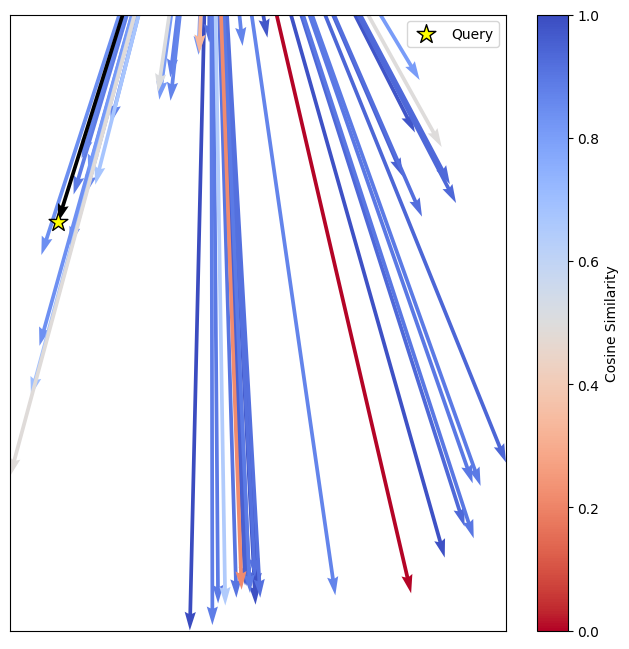

In [17]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()

# Clustering

## Hierarchical

In [18]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [19]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

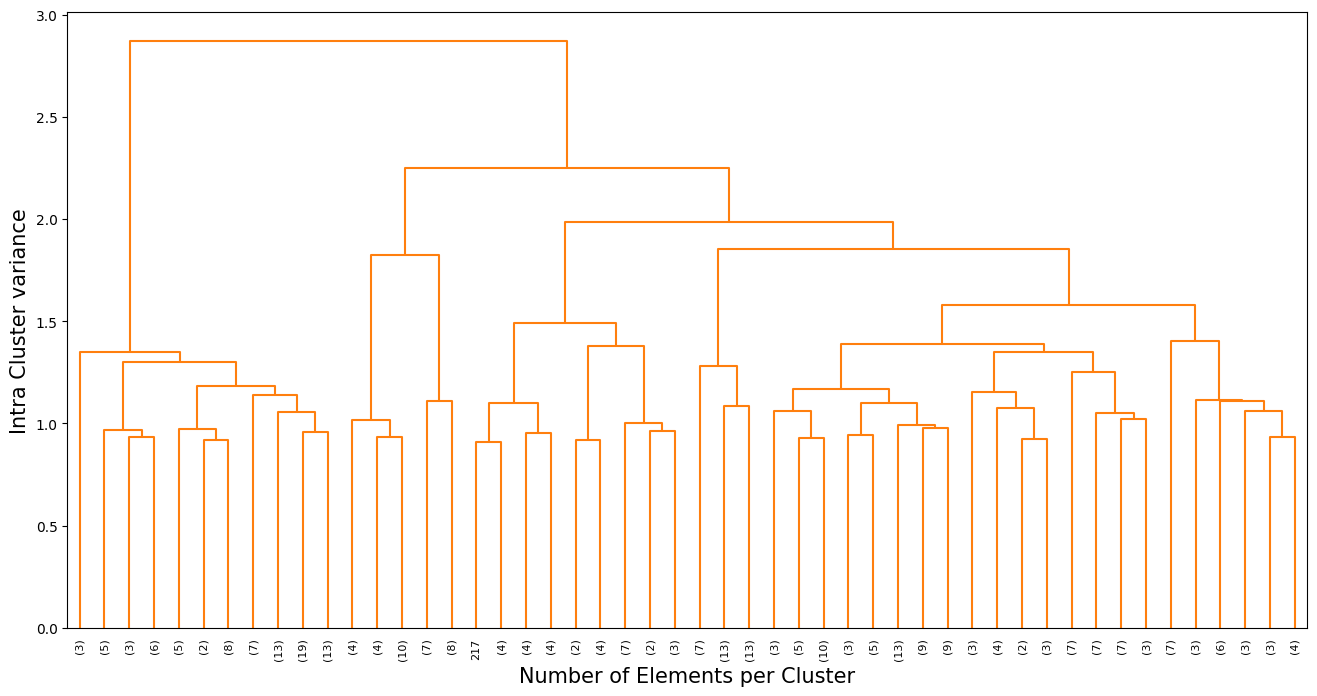

In [20]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
# dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=3.3553076382448)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [21]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 2.250706633968332,
 4: 1.9850252727477973,
 5: 1.8540813016860853,
 6: 1.8248361910776727,
 7: 1.5800236943735761,
 8: 1.489252831644969,
 9: 1.40180302133589,
 10: 1.3899837845817624,
 11: 1.3786360310231782,
 12: 1.351375010909802,
 13: 1.3468998800359278,
 14: 1.3015258139234271,
 15: 1.2786110848054841,
 16: 1.2490625309424852,
 17: 1.1820273688684653,
 18: 1.167296577497838,
 19: 1.1547736146724472,
 20: 1.1393559040660917,
 21: 1.1128933822747813,
 22: 1.1114545399053288,
 23: 1.111337087720179,
 24: 1.1018904152160767,
 25: 1.100834647171339,
 26: 1.083031940524344,
 27: 1.0736150211932132,
 28: 1.062936424756043,
 29: 1.0588570736282377,
 30: 1.0564471733377732,
 31: 1.050187960294268,
 32: 1.0203925362361659,
 33: 1.0171178105911636,
 34: 1.0040299420299073,
 35: 0.994020929133836,
 36: 0.9760679491642417,
 37: 0.9749951146440674,
 38: 0.9670766153531709,
 39: 0.9646315747167844,
 40: 0.9600673768177493,
 41: 0.9508998904819856,
 42: 0.9425692568687727,
 43: 0.934913377517

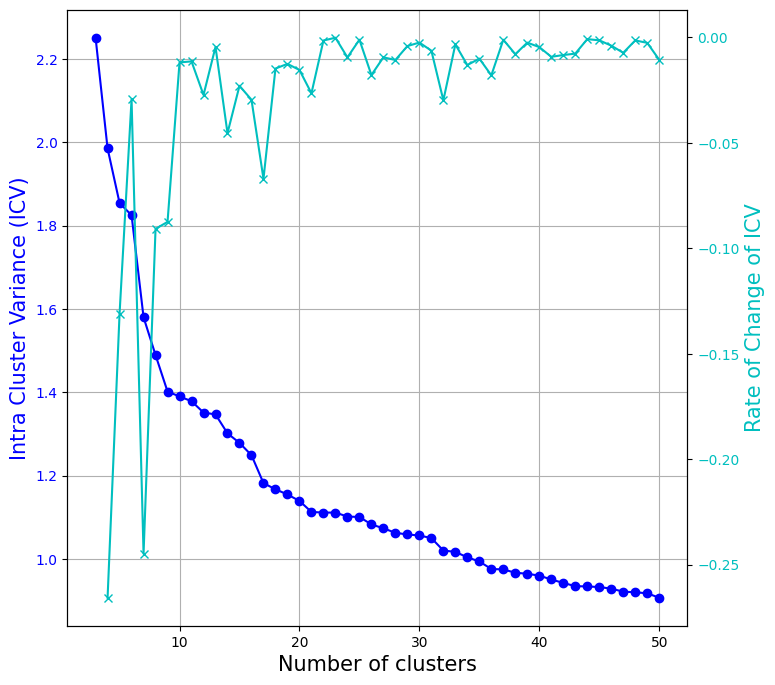

In [22]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [23]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [24]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [25]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [26]:
k = 5
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4]


In [27]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4]


cluster_HC
4    119
0     84
1     33
3     33
2     31
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [28]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [29]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [30]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [31]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [32]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [33]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [34]:
# UMAP 2D

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

custom_colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", 
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#f6a828"
]

custom_colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", 
    "#8c564b"
]

# Crear gráfico de dispersión interactivo
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,
    color_discrete_sequence=custom_colors,
    hover_data=[clustering_method, 'title'],
    hover_name='title',
    opacity=0.7,
    category_orders={clustering_method: clusters}
)

# Fondo blanco, grilla visible y ejes definidos
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    xaxis=dict(
        title='umap2d_1',
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        zeroline=False,
        scaleanchor="y"
    ),
    yaxis=dict(
        title='umap2d_2',
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        zeroline=False,
        scaleanchor="x"
    ),
    width=800,
    height=800,
    legend_title_text='Cluster',
    legend_title_font_size=20,  # Tamaño más grande para el título de la leyenda
    legend_font_size=18,        # Tamaño más grande para el texto de la leyenda
    legend_tracegroupgap=10,    # Espaciado entre grupos de leyenda
    legend_traceorder='normal', # Orden normal de leyenda
    legend_itemwidth=30,        # Ancho de los elementos de la leyenda
    legend_itemsizing='constant' # Mantener el tamaño de los símbolos constante
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Agregar puntos resaltados (KNNs) en rojo
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],
    hovertext=df.loc[knn_idxs[0], 'title'],
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Asociar colores a cada cluster
cluster_colors = dict(zip(df[clustering_method].cat.categories, custom_colors))

# Agregar centroides con los colores correspondientes
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=12, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',
        showlegend=False
    )

# Guardar gráfico como PDF
fig.write_image("../data/output/UMAP.pdf")

# Mostrar gráfico
fig.show()

C:\Users\Ingeniería Eléctrica\AppData\Local\Temp\ipykernel_12452\3037923526.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Summarization
Importantest words by Tf-Idf score

In [35]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [36]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['control', 'voltage', 'current', 'converter', 'predictive', 'multilevel', 'model', 'frequency', 'capacitor', 'modular']


### Clusters

In [37]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 5)
    print(f'Cluster {cluster}: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

Cluster 0: control, predictive, voltage, model, current
Cluster 1: control, matrix, frequency, voltage, low
Cluster 2: control, loop, closed, voltage, impedance
Cluster 3: current, voltage, control, circulating, controller
Cluster 4: control, voltage, current, converter, capacitor


# Hierarchical conceptual map

In [38]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [39]:
# def encontrar_mas_cercano_al_centroide(df_vectorized, data):
#     centroide = df_vectorized.mean(axis=0)
#     distancias = euclidean_distances(df_vectorized, [centroide])
#     indice_mas_cercano = np.argmin(distancias)
#     texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
#     titulo = data.iloc[indice_mas_cercano]['title']
#     return titulo, texto_mas_cercano

### Corpus

In [40]:
# titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
# display(f"Texto mas representativo del corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {texto_mas_cercano}")

### Clusters

In [41]:
# for cluster in clusters:
#     cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
#     cluster_data = data[df[clustering_method] == cluster]
#     titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
#     display(f"Cluster {cluster}: Texto mas cercano al centroide")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {texto_mas_cercano}")

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [42]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: a control strategy for modular multilevel converters based on arm current control under grid side open circuit fault'

'Abstract: to further improve the power supply sustainability of the ac dc hybrid distribution networks this paper proposes a control strategy for the modular multilevel converter mmc under grid side open circuit fault which is based on independent arm current control firstly the behaviors of the mmc after the faults are analyzed including single phase and two phase open circuit faults for single phase open circuit fault the proposed strategy can be achieved by reconfiguring the amplitude and phase of the arm currents thereby eliminating the zero sequence current for two phase open circuit fault both the arm currents and voltages need to be reconfigured after that a method for detecting and locating specific faults is provided which can be implemented by detecting the amplitude of the zero sequence current besides the postfault characteristics of the mmc under single phase open circuit condition are given including submodule sm capacitor voltage ripple circulating current arm rms curre

### Clusters

In [43]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

"Cluster 0: ['control', 'predictive', 'voltage', 'model', 'current', 'converter', 'multilevel', 'mpc', 'switching', 'strategy']"

'Título: a coordination control method for multi terminal ac dc hybrid system based on mmc transmission technology'

'Abstract: in the voltage source converter based multiterminal high voltage direct current system vsc mtdc the power electronic topology of the modular multilevel converter mmc determines its characteristics of zero rotational inertia and the fluctuation of dc transmission power may lead to short time power imbalance in the ac system connected with the inverter however the response speed of thermal power unit can not complete frequency adjustment in a short time regarding this kind of problem combined with the improved droop control idc method of the converter a comprehensive control method of inverter based on virtual synchronous generator vsg is proposed in this paper firstly on basis of analysis that the control mechanism and shortcomings of the improved droop control method for vsc mtdc system a vsg control method for the inverter with inertial response and primary frequency modulation is proposed secondly the stability of the system is analyzed based on the second order mathematic

"Cluster 1: ['control', 'matrix', 'frequency', 'voltage', 'low', 'converter', 'current', 'mode', 'drive', 'speed']"

'Título: 3kw four level flying capacitor totem pole bridgeless pfc rectifier with 200v gan devices'

...

'Título: a fault ride through method based on energy dissipation device in the scenario of flexible hvdc grid connection of offshore wind power'

'Abstract: the flexible hvdc transmission technology based on the modular multilevel converter mmc topology has a very broad application prospect in the process of large scale renewable energy collection and transmission this technology has become one of the best choices for long distance offshore wind power farms to connect to the onshore power grid in view of the special working conditions such as overvoltage in the fault state this article proposes a controllable large capacity self recovery energy dissipation device for the first time to improve the transient characteristics of the dc and ac power system the proposed scheme has the advantages of no harmonic generation during operation relatively simple control strategy and high current impact resistance the electromagnetic transient simulation shows that the proposed scheme can effectively solve the overvoltage problem of dc in the offshore wind power flexible hvdc system and improve the reliability of the hvdc system'

"Cluster 4: ['control', 'voltage', 'current', 'converter', 'capacitor', 'multilevel', 'power', 'balancing', 'frequency', 'modular']"

'Título: a control strategy for modular multilevel converters based on arm current control under grid side open circuit fault'

'Abstract: to further improve the power supply sustainability of the ac dc hybrid distribution networks this paper proposes a control strategy for the modular multilevel converter mmc under grid side open circuit fault which is based on independent arm current control firstly the behaviors of the mmc after the faults are analyzed including single phase and two phase open circuit faults for single phase open circuit fault the proposed strategy can be achieved by reconfiguring the amplitude and phase of the arm currents thereby eliminating the zero sequence current for two phase open circuit fault both the arm currents and voltages need to be reconfigured after that a method for detecting and locating specific faults is provided which can be implemented by detecting the amplitude of the zero sequence current besides the postfault characteristics of the mmc under single phase open circuit condition are given including submodule sm capacitor voltage ripple circulating current arm rms curre

## Similaridad del coseno

### Corpus

In [44]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def RepresentanteCoseno(matrix_vectors):
    """
    Retorna el índice del texto más representativo del conjunto (más similar al resto).
    
    Parameters:
    - matrix_vectors: matriz (numpy array o pandas DataFrame) donde cada fila es un vector (TF-IDF o embedding)
    
    Returns:
    - Índice del texto más representativo
    """
    # Asegura que sea array de NumPy
    if hasattr(matrix_vectors, 'values'):
        matrix_vectors = matrix_vectors.values

    # Calcular matriz de similitud coseno
    similitudes = cosine_similarity(matrix_vectors)
    
    # Sumar similitudes por fila (suma de cada vector con todos los demás)
    suma_similitudes = np.sum(similitudes, axis=1)
    
    # Retornar índice del vector con mayor similitud total
    return np.argmax(suma_similitudes)


In [45]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: 35kv 200mvar transformerless statcom based on cascaded h bridge multilevel converter'

'Abstract: deregulation and liberalization of international energy market are recently increasing the demand in transmission and distribution networks for more efficient solutions for power management and better power quality fast and reliable var control systems such as statcoms enhance the dynamic stability of power networks rongxin power electronic co rxpe developed a transformerless cascaded h bridge multilevel converter to be directly connected to 35 kv grid after an overview of statcom topologies and semiconductor devices section i and ii some test results in factory is introduced'

### Clusters

In [46]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

"Cluster 0: ['control', 'predictive', 'voltage', 'model', 'current', 'converter', 'multilevel', 'mpc', 'switching', 'strategy']"

'Título: a bidirectional modular multilevel dc dc converter of triangular structure'

'Abstract: in this paper a novel bidirectional modular multilevel dc dc converter is proposed the proposed topology named the triangular modular multilevel dc dc converter tmmc can achieve equal power sharing among its modules over a broad range of conversion ratios the proposed control algorithm provides localized control of modules which enhances the converter s dynamic performance and design flexibility a 1 7 kw experimental implementation of the converter is shown to achieve an efficiency of 95 9 and 96 2 in step up and step down modes respectively significant reductions in the input current and output voltage ripples are observed through the interleaved operation of the converter the tmmc also provides multiple fixed voltage nodes which makes it suitable as a multiple input multiple output converter'

"Cluster 1: ['control', 'matrix', 'frequency', 'voltage', 'low', 'converter', 'current', 'mode', 'drive', 'speed']"

'Título: a 3 3kv igbt module and application in modular multilevel converter for hvdc'

...

'Título: 21 level csd based solar multilevel inverter fed induction motor drive'

'Abstract: as the demand for electricity increases renewable energy is considered to be the most promising distribution today comprehending an advanced solar multilevel inverter with soaring feat by denominating a customization system configuration the modular configuration consists of a dc dc converter module and a dc ac inverter module the dc bus acts as a modern shared record provider between them realize parallel and redundant operation of inverter modules unless there is no verbal communication link between them here the new inverter topology is utilized to the system the cascaded switching diode multilevel inverter was selected as a safe and suitable topology because of its flexibility of control and a small range of switches are regarded its foremost advantages the duty cycle exchange control provided to the multilevel inverter helps stabilize the dc energy supply this control aids in the power distribution around the switches this monitoring helps to cut down on heat and conduc

"Cluster 4: ['control', 'voltage', 'current', 'converter', 'capacitor', 'multilevel', 'power', 'balancing', 'frequency', 'modular']"

'Título: 35kv 200mvar transformerless statcom based on cascaded h bridge multilevel converter'

'Abstract: deregulation and liberalization of international energy market are recently increasing the demand in transmission and distribution networks for more efficient solutions for power management and better power quality fast and reliable var control systems such as statcoms enhance the dynamic stability of power networks rongxin power electronic co rxpe developed a transformerless cascaded h bridge multilevel converter to be directly connected to 35 kv grid after an overview of statcom topologies and semiconductor devices section i and ii some test results in factory is introduced'

# Grafo de palabras

## Palabras de un abstract especifico

In [47]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters